# Execute the code below

In [1]:
import pandas as pd
import numpy as np
link = "https://raw.githubusercontent.com/WildCodeSchool/data-training-resources/main/quests/weather2019.csv"
df_weather = pd.read_csv(link)

In [ ]:
#columns = colonnes
#index = lignes
#values = valeurs
#aggfunc = fonction d'agrégation

# You have now a DataFrame with lots of weather data

In [2]:
df_weather.head()

,DATE,MAX_TEMPERATURE_C,MIN_TEMPERATURE_C,WINDSPEED_MAX_KMH,TEMPERATURE_MORNING_C,TEMPERATURE_NOON_C,TEMPERATURE_EVENING_C,PRECIP_TOTAL_DAY_MM,HUMIDITY_MAX_PERCENT,VISIBILITY_AVG_KM,...,WINDTEMP_MAX_C,WEATHER_CODE_MORNING,WEATHER_CODE_NOON,WEATHER_CODE_EVENING,TOTAL_SNOW_MM,UV_INDEX,SUNHOUR,OPINION,MONTH,DAY
0,2019-01-01,9,4,10,4,7,8,0.2,94,9.0,...,3,116,143,176,0,1,5.1,very bad,1,1
1,2019-01-02,8,5,18,7,7,5,0.0,90,9.0,...,3,119,116,116,0,1,8.7,very bad,1,2
2,2019-01-03,6,0,18,0,4,3,0.0,88,10.0,...,-4,116,116,116,0,1,8.7,very bad,1,3
3,2019-01-04,5,-1,15,-1,4,3,0.0,91,10.0,...,-4,116,116,122,0,1,5.1,very bad,1,4
4,2019-01-05,6,-1,8,-1,4,3,0.0,91,8.0,...,-2,143,116,116,0,1,8.7,very bad,1,5


# PIVOT TABLE

## It's like in Excel, but with Pandas

There are 2 syntaxes, choose your preferred :
- As a method : YOUR_DATAFRAME.pivot_table()
- As a function : pd.crosstab()

In [3]:
# Example
df_weather.pivot_table(values = 'MAX_TEMPERATURE_C', index = 'MONTH', aggfunc = 'mean')

,MAX_TEMPERATURE_C
MONTH,
1,8.161290
2,12.750000
3,13.064516
4,14.900000
5,16.870968
6,22.166667
7,26.806452
8,25.290323
9,22.533333


## Create a Pivot table with :
- Months on rows
- the maximum of Max Temperature on values
- Opinion on columns

In [4]:
# Hop !
df_weather.pivot_table(
    values= "MAX_TEMPERATURE_C",
    index= "MONTH",
    aggfunc= "max"
)

,MAX_TEMPERATURE_C
MONTH,
1,11
2,20
3,19
4,24
5,25
6,34
7,39
8,33
9,31


## Pivot table with :
- Days on rows
- Precipitation on values
- Months on columns


In [5]:
# Hop !
df_weather.pivot_table(columns = 'MONTH',
                       index = 'DAY',
                       values = 'PRECIP_TOTAL_DAY_MM')

MONTH,1,2,3,4,5,6,7,8,9,10,11,12
DAY,,,,,,,,,,,,
1,0.2,7.3,0.0,2.0,6.0,0.0,1.0,0.0,0.0,5.7,14.5,0.0
2,0.0,1.0,4.9,1.8,0.4,0.0,0.0,0.0,0.0,0.2,11.0,0.0
3,0.0,0.0,5.4,5.2,0.5,0.5,0.0,0.0,0.0,0.3,30.0,0.0
4,0.0,18.6,11.1,1.1,0.6,6.3,0.0,0.0,0.3,1.1,4.2,0.0
5,0.0,0.8,1.1,10.1,0.3,1.5,0.6,0.1,0.0,0.4,8.0,0.0
6,0.0,9.4,47.6,6.1,0.0,2.7,7.5,4.4,0.0,1.5,1.1,0.3
7,0.0,4.0,3.4,3.0,1.2,27.3,1.7,0.1,0.2,4.3,11.4,0.4
8,0.2,1.6,0.2,1.6,17.8,3.4,0.0,0.0,0.0,3.9,3.2,9.1
9,0.0,6.3,5.3,0.8,4.4,4.0,0.0,5.5,8.4,2.6,10.1,0.6


## Pivot table with :
- Months on rows
- the sum of Precipitations on values

**Then display it as a column chart.** (optionnal)

In [7]:
# Hop !
sum_precipitation = df_weather.pivot_table(index = 'MONTH',
                       values = 'PRECIP_TOTAL_DAY_MM',
                       aggfunc = 'sum')
sum_precipitation

,PRECIP_TOTAL_DAY_MM
MONTH,
1,58.2
2,82.5
3,103.4
4,99.7
5,71.6
6,77.2
7,40.6
8,33.2
9,60.1


<Axes: xlabel='MONTH'>

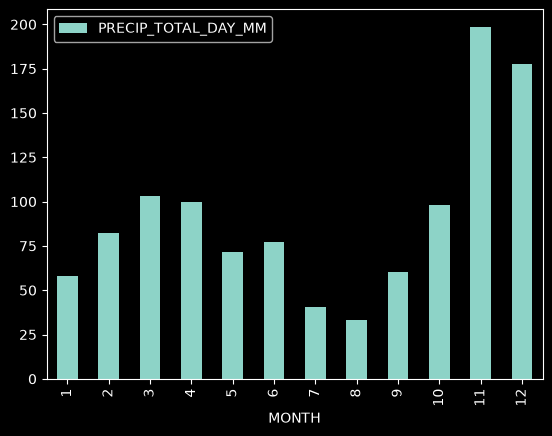

In [8]:
sum_precipitation.plot.bar()

## Pivot table with :
- Months on rows
- the average of Max Temperature on a first column of values
- the average of Sunhours on a second column of values

In [9]:
# Hop !
avg_temp_sunhour = df_weather.pivot_table(index = 'MONTH',
                       values = ['MAX_TEMPERATURE_C', 'SUNHOUR'],
                       aggfunc = 'mean')
avg_temp_sunhour

,MAX_TEMPERATURE_C,SUNHOUR
MONTH,,
1,8.161290,5.709677
2,12.750000,8.346429
3,13.064516,9.077419
4,14.900000,9.533333
5,16.870968,11.809677
6,22.166667,14.170000
7,26.806452,14.141935
8,25.290323,11.135484
9,22.533333,9.683333


# Chart
Using your favorite library (MatPlotLib, Seaborn, Plotly or what you want), draw a chart from the previous pivot table with :
- Temperature in a blue column chart
- Sunhours in a red line plot

Tip : Once your pivot table created, you can help yourself with the `.reset_index()`  method.

In [10]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, "Moyenne de température et ensoleillement mensuels de l'année 2019")

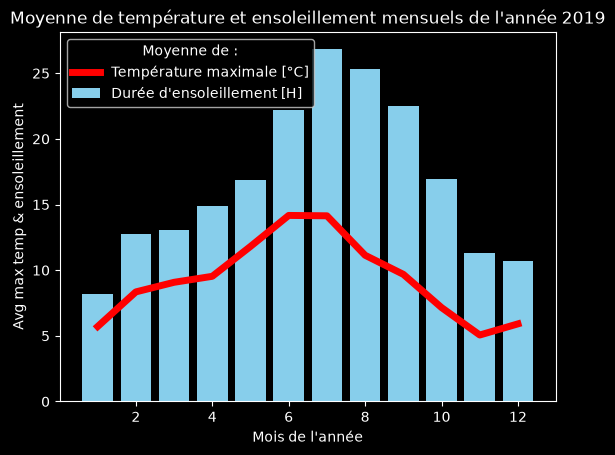

In [11]:
# Your code here
plt.bar(x = avg_temp_sunhour.index, height = avg_temp_sunhour['MAX_TEMPERATURE_C'], color = 'skyblue')
plt.plot(avg_temp_sunhour['SUNHOUR'], c = 'red', lw = 5)
plt.xlabel("Mois de l'année")
plt.ylabel("Avg max temp & ensoleillement")
plt.legend(['Température maximale [°C]', "Durée d'ensoleillement [H]"], title = "Moyenne de :")
plt.title("Moyenne de température et ensoleillement mensuels de l'année 2019")